# Рекомендательная система поисковых кластеров: демонстрация

## Главное: стала ли система находить больше продающих запросов?

**Начните с графика и примеров ниже.** Их выводы сохранены: на GitHub ничего запускать не нужно.

Проверяем на реальной истории:
1. Даём обоим вариантам только прошлую историю.
2. Каждый вариант выбирает **10 запросов для товара**.
3. Смотрим следующие **14 дней**: какие запросы действительно принесли заказы?

**Базовый вариант** — E5 + совместные продажи. **Полная система** — те же каналы плюс обученные адаптер и LightGCN. Пул кандидатов одинаковый; веса выбраны до проверки.

Ниже ноутбук сам пересчитывает результат из [обезличенных позиций](reports/notebook_ranking_pairs.csv) **всех будущих продающих пар**, включая не найденные поиском. Это проверка ранее сохранённого ранжирования, не новое обучение. Реальные номера товаров и тексты запросов заменены условными обозначениями.

> Это диагностическая историческая проверка: сентябрьский период уже использовался в исследованиях. Она показывает улучшение отбора запросов, **не рост продаж и не улучшение поискового движка Ozon**. На четырёх новых днях уверенное независимое подтверждение пока не получено.

Дальше, в разделах 1–7, показана работа моделей по ячейкам. Там данные **синтетические**, код моделей настоящий; учебные метрики не доказывают качество на реальных данных. Подробности реальной оценки — в разделе 8.

**Для повторения:** установите `requirements.txt`, откройте ноутбук в Jupyter или PyCharm и выполните **Restart Kernel → Run All**. База данных, ClickHouse и `.env` не нужны. Первые ячейки с реальным сравнением работают без скачивания моделей; учебный запуск далее скачает E5 (~500 МБ) и использует CPU.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SUMMARY_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'src/recommender.py').is_file()), None)
if SUMMARY_ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки клонированного проекта.')
sys.path.insert(0, str(SUMMARY_ROOT / 'src'))
from ranking_snapshot import snapshot_metrics

pair_path = SUMMARY_ROOT / 'reports/notebook_ranking_pairs.csv'
snapshot_info = json.loads((SUMMARY_ROOT / 'reports/notebook_ranking_manifest.json').read_text())
summary_path = SUMMARY_ROOT / 'reports/experiment_summary.json'
assert hashlib.sha256(pair_path.read_bytes()).hexdigest() == snapshot_info['pairs_sha256']
assert hashlib.sha256(summary_path.read_bytes()).hexdigest() == snapshot_info['experiment_summary_sha256']
real_pairs = pd.read_csv(pair_path, dtype={'baseline_rank': 'Int64', 'system_rank': 'Int64'})
summary_report = json.loads(summary_path.read_text())
assert set(real_pairs['period']) == {'test', 'new_days'}
measured_periods = {}
for period in ['test', 'new_days']:
    measured_periods[period] = snapshot_metrics(real_pairs.loc[real_pairs.period.eq(period)])
    for method, reference in [('baseline', 'e5_co_sales'), ('system', 'all_four')]:
        expected_metrics = summary_report['ablation'][period][reference]
        for metric_name in ['recall@10', 'precision@10', 'ndcg@10', 'retrieval_recall',
                            'evaluated_skus', 'positive_pairs']:
            assert np.isclose(measured_periods[period][method][metric_name],
                              expected_metrics[metric_name], rtol=1e-10, atol=1e-12)

real_test = real_pairs.loc[real_pairs.period.eq('test')].copy()
real_metrics = measured_periods['test']
print(f"Проверено: {len(real_test)} будущих продающих пар, {real_test.product_id.nunique()} товар.")
print('Позиции прочитаны из CSV; метрики пересчитаны и совпали с исходным отчётом.')

Проверено: 260 будущих продающих пар, 121 товар.
Позиции прочитаны из CSV; метрики пересчитаны и совпали с исходным отчётом.


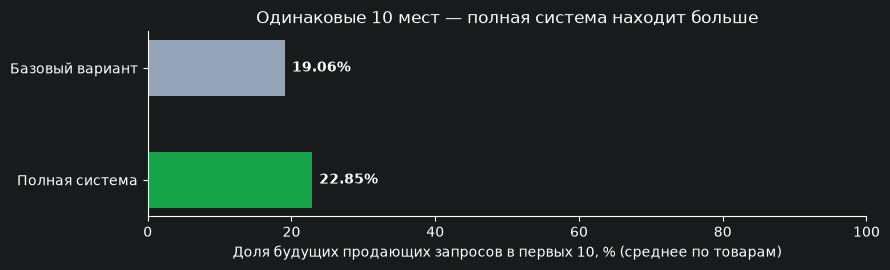

**Результат: 19.06% → 22.85%. Прирост +3.79 процентного пункта (около +20% относительно базы).** Это полнота рекомендаций на исторической проверке, **не прирост продаж**.

,Найдено будущих продающих пар,Всего будущих продающих пар
Вариант,,
Базовый вариант,51,260
Полная система,60,260


Число попаданий — общий счёт. Процент на графике — среднее долей по товарам, а не общий счёт / 260.


In [2]:
import matplotlib.pyplot as plt

comparison_names = ['Базовый вариант', 'Полная система']
recall_values = [100 * real_metrics[name]['recall@10'] for name in ['baseline', 'system']]
fig, ax = plt.subplots(figsize=(9, 2.8))
bars = ax.barh(comparison_names, recall_values, color=['#94a3b8', '#16a34a'], height=0.5)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('Доля будущих продающих запросов в первых 10, % (среднее по товарам)')
ax.set_title('Одинаковые 10 мест — полная система находит больше')
for bar, value in zip(bars, recall_values):
    ax.text(value + 1, bar.get_y() + bar.get_height() / 2, f'{value:.2f}%', va='center', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()
plt.close(fig)

recall_gain = recall_values[1] - recall_values[0]
relative_gain = 100 * recall_gain / recall_values[0]
display(Markdown(f'**Результат: {recall_values[0]:.2f}% → {recall_values[1]:.2f}%. '
                 f'Прирост +{recall_gain:.2f} процентного пункта (около +{relative_gain:.0f}% относительно базы).** '
                 'Это полнота рекомендаций на исторической проверке, **не прирост продаж**.'))
display(pd.DataFrame({
    'Вариант': comparison_names,
    'Найдено будущих продающих пар': [real_metrics[name]['hits'] for name in ['baseline', 'system']],
    'Всего будущих продающих пар': [len(real_test)] * 2,
}).set_index('Вариант'))
print('Число попаданий — общий счёт. Процент на графике — среднее долей по товарам, а не общий счёт / 260.')

### На каких запросах это видно?

**Пример выигрыша:** база поставила запрос ниже 10-го места, система подняла в первые 10, а позже по нему был заказ. Показываем и обратные случаи — система не выигрывает на каждом запросе.

`P…` — условный номер товара, `Q…` — условный номер реального поискового кластера. **Все строки исходного CSV — будущие продающие пары**, а не список всех рекомендаций. «Не найден» означает отсутствие в пуле кандидатов; такая цель всё равно участвует в оценке. Общий результат выше рассчитан по всем 260 парам, не только по примерам ниже.

In [3]:
baseline_hit = real_test['baseline_rank'].le(10).fillna(False)
system_hit = real_test['system_rank'].le(10).fillna(False)
gained = real_test.loc[system_hit & ~baseline_hit]
lost = real_test.loc[baseline_hit & ~system_hit]
shared = int((baseline_hit & system_hit).sum())
neither = int((~baseline_hit & ~system_hit).sum())
print(f'Полная система нашла, база пропустила: {len(gained)} пар.')
print(f'База нашла, полная система пропустила: {len(lost)} пар.')
print(f'Нашли оба варианта: {shared}. Не попали в первые 10 ни у одного: {neither}.')
assert len(gained) + len(lost) + shared + neither == len(real_test)

example_pairs = pd.concat([
    gained.head(3).assign(Итог='Выигрыш системы'),
    lost.head(3).assign(Итог='Потеря системы'),
])

def readable_rank(value):
    if pd.isna(value):
        return 'Не найден'
    return f'{int(value)} — в первых 10' if value <= 10 else f'{int(value)} — вне первых 10'

example_table = example_pairs[['product_id', 'query_id', 'Итог']].rename(
    columns={'product_id': 'Товар', 'query_id': 'Запрос'})
example_table['Место у базы'] = example_pairs['baseline_rank'].map(readable_rank)
example_table['Место у системы'] = example_pairs['system_rank'].map(readable_rank)
example_table['Заказ в следующие 14 дней'] = 'Да'
display(example_table.set_index(['Товар', 'Запрос']))

new_comparison = measured_periods['new_days']
new_interval = summary_report['ablation']['new_days_full_minus_control']
display(Markdown(
    f"**Дополнительная проверка, 04–07.10 (только 4 дня):** "
    f"{100 * new_comparison['baseline']['recall@10']:.2f}% → "
    f"{100 * new_comparison['system']['recall@10']:.2f}%. "
    f"95% интервал прироста: [{100 * new_interval['lower']:.2f}; "
    f"{100 * new_interval['upper']:.2f}] п.п. Включает ноль: "
    '**уверенного независимого подтверждения пока нет**.'))

Полная система нашла, база пропустила: 16 пар.
База нашла, полная система пропустила: 7 пар.
Нашли оба варианта: 44. Не попали в первые 10 ни у одного: 193.


,,Итог,Место у базы,Место у системы,Заказ в следующие 14 дней
Товар,Запрос,,,,
P0030,Q0019,Выигрыш системы,15 — вне первых 10,3 — в первых 10,Да
P0047,Q0017,Выигрыш системы,80 — вне первых 10,10 — в первых 10,Да
P0049,Q0152,Выигрыш системы,15 — вне первых 10,8 — в первых 10,Да
P0007,Q0321,Потеря системы,5 — в первых 10,12 — вне первых 10,Да
P0013,Q0323,Потеря системы,4 — в первых 10,29 — вне первых 10,Да
P0020,Q0307,Потеря системы,3 — в первых 10,13 — вне первых 10,Да


**Дополнительная проверка, 04–07.10 (только 4 дня):** 15.14% → 17.95%. 95% интервал прироста: [-2.08; 7.92] п.п. Включает ноль: **уверенного независимого подтверждения пока нет**.

---

## Дальше: как работают модели

Главное реальное сравнение уже показано выше. Теперь пройдём небольшой учебный пример: данные → обучение → рекомендации → защитная фильтрация. **Здесь товары и события вымышленные**, чтобы можно было быстро повторить запуск без доступа к базе.

Модели вызываются напрямую из `src/`: E5 кодирует тексты, адаптер и LightGCN обучаются, CatBoost выступает альтернативным ранжировщиком. Полная система не меняет карточки автоматически — формирует очередь для ручной проверки.

In [4]:
from pathlib import Path
from datetime import date
from importlib.metadata import version
import hashlib
import json
import os
import sys
import tempfile
import warnings

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/recommender.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Откройте ноутбук из папки клонированного проекта.')
sys.path.insert(0, str(ROOT / 'src'))
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
warnings.filterwarnings('ignore', message='IProgress not found.*')

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from cluster_recommender import HybridRetriever, lexical_index
from dormant_learning import learning_rows, fit_ranker, fit_fusion, ranking_metrics
from semantic_adapter import fit_adapter, apply_adapter
from graph_learning import fit_graph
from full_history_recommender import DormantConfig, enrich_candidates, graph_vectors, refinement_scores
from seo_recommendation_policy import annotate_recommendations, review_top_k

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
pd.set_option('display.max_colwidth', 65)
RUN_PRIVATE_CHECK = (ROOT / 'reports/stage3_release/manifest.json').is_file()
# Можно поставить False: приватный релиз не нужен для учебных разделов 1–8.
print('Готово: seed = 7, CPU; база данных не используется.')
display(pd.DataFrame([(name, version(name)) for name in
    ['numpy', 'pandas', 'torch', 'sentence-transformers', 'catboost']],
    columns=['Библиотека', 'Версия']))

Готово: seed = 7, CPU; база данных не используется.


,Библиотека,Версия
0,numpy,2.5.3
1,pandas,3.0.6
2,torch,2.14.1
3,sentence-transformers,5.7.0
4,catboost,1.2.10


## 1. Данные и защита от подсматривания в будущее

Три вымышленных товара: мусорные пакеты 60 л, салфетки из микрофибры, нитриловые перчатки. Есть похожие товары-соседи, по которым уже известны продающие запросы. В каталоге намеренно оставлены неподходящие запросы: другой объём, другой материал, другое назначение.

**Временной протокол учебного запуска:** история для E5-адаптера и LightGCN — по 07.08; цели для CatBoost — 08–21.08; validation для выбора весов — 22.08–04.09; test — 05–18.09. В test веса и обученные нейросети уже фиксированы. Для каждого решения поиску доступна только предшествующая история. Нулевые заказы означают неизвестный ответ, а не доказанную нерелевантность.

In [5]:
groups = {
    '101': ['пакеты для мусора', 'мешки мусорные 60 л', 'пакеты мусорные прочные',
            'мешки для мусора с завязками', 'пакеты для мусора плотные',
            'пакеты для мусора черные', 'пакеты для мусора 120 л', 'пакеты для заморозки'],
    '102': ['салфетки из микрофибры', 'салфетки для уборки', 'тряпки для уборки микрофибра',
            'салфетки для стекол', 'салфетки для пыли', 'салфетки универсальные',
            'салфетки из целлюлозы', 'губки для посуды'],
    '103': ['перчатки нитриловые', 'перчатки одноразовые', 'перчатки нитриловые без пудры',
            'перчатки для уборки нитриловые', 'перчатки защитные нитриловые',
            'перчатки хозяйственные', 'перчатки латексные', 'перчатки виниловые'],
}
catalog = sorted({q for queries in groups.values() for q in queries})
products = pd.DataFrame([
    ['101', 'Пакеты для мусора 60 л', 'Прочные мешки для бытового мусора.', 'Учебный бренд'],
    ['102', 'Салфетки из микрофибры', 'Для домашней уборки поверхностей.', 'Учебный бренд'],
    ['103', 'Перчатки нитриловые', 'Одноразовые защитные перчатки.', 'Учебный бренд'],
], columns=['sku', 'name', 'description', 'brand']).assign(
    attributes_json='[]', attributes_status='ok', snapshot_at='2026-08-01T00:00:00Z')

records = []
for sku, queries in groups.items():
    peer = str(int(sku) + 100)
    for decision in ['2026-08-07', '2026-08-21', '2026-09-04']:
        for q in queries[:2]:
            records.append([decision, sku, q, 3, 15, 30, 1])
        for q in queries[:5]:
            records.append([decision, peer, q, 2, 10, 20, 1])
        records.append([decision, sku, queries[5], 0, 12, 30, 1])
    for day, q in zip(['2026-08-08', '2026-08-22', '2026-09-05'], queries[2:5]):
        records.append([day, sku, q, 1, 2, 10, 1])
events = pd.DataFrame(records, columns=['date', 'sku', 'normquery', 'orders', 'views', 'searches', 'days'])
events['date'] = pd.to_datetime(events['date'])
config = DormantConfig(date(2026, 8, 1), date(2026, 8, 7), date(2026, 8, 21),
    date(2026, 9, 4), window_days=14, per_source=12, iterations=(40,), seed=SEED)
train_events = events.loc[events['date'].le('2026-08-07')].copy()
assert not events.isna().any().any()
assert train_events['date'].max() < pd.Timestamp('2026-08-08')
print(f'Учебные данные: {len(events)} событий, {events.sku.nunique()} SKU, {len(catalog)} кластеров.')
print('Пропуски:', int(events.isna().sum().sum()), '| История и будущие цели разделены.')
display(products[['sku', 'name']])
display(events.head(8))
display(pd.DataFrame({'Поле': events.columns, 'Тип': events.dtypes.astype(str).values}))

Учебные данные: 81 событий, 6 SKU, 24 кластеров.
Пропуски: 0 | История и будущие цели разделены.


,sku,name
0,101,Пакеты для мусора 60 л
1,102,Салфетки из микрофибры
2,103,Перчатки нитриловые


,date,sku,normquery,orders,views,searches,days
0,2026-08-07,101,пакеты для мусора,3,15,30,1
1,2026-08-07,101,мешки мусорные 60 л,3,15,30,1
2,2026-08-07,201,пакеты для мусора,2,10,20,1
3,2026-08-07,201,мешки мусорные 60 л,2,10,20,1
4,2026-08-07,201,пакеты мусорные прочные,2,10,20,1
5,2026-08-07,201,мешки для мусора с завязками,2,10,20,1
6,2026-08-07,201,пакеты для мусора плотные,2,10,20,1
7,2026-08-07,101,пакеты для мусора черные,0,12,30,1


,Поле,Тип
0,date,datetime64[us]
1,sku,str
2,normquery,str
3,orders,int64
4,views,int64
5,searches,int64
6,days,int64


## 2. Предобученная E5: смысловое сходство текстов

E5 превращает запросы в нормированные векторы: близкие по смыслу тексты имеют высокое скалярное произведение. Для кластеров используется тот же префикс `query:`, что и в основном пайплайне. Веса E5 не дообучаем; фиксируем ревизию модели для повторяемости.

Ниже видны реальные ближайшие тексты. Даже хороший смысловой score не доказывает пригодность запроса: например, 120 л и 60 л могут оказаться близкими. Это объясняет необходимость отдельной защиты.

In [6]:
from sentence_transformers import SentenceTransformer

MODEL_ID = 'intfloat/multilingual-e5-small'
REVISION = '614241f622f53c4eeff9890bdc4f31cfecc418b3'
cache = ROOT / 'data/model_cache'
local_model = cache / 'hub/models--intfloat--multilingual-e5-small/snapshots' / REVISION
if (local_model / 'modules.json').is_file():
    encoder = SentenceTransformer(str(local_model), device='cpu', local_files_only=True)
else:
    encoder = SentenceTransformer(MODEL_ID, revision=REVISION, device='cpu', cache_folder=str(cache))
vectors = encoder.encode(['query: ' + q for q in catalog], batch_size=24,
    normalize_embeddings=True, show_progress_bar=False).astype(np.float32)
assert vectors.shape == (len(catalog), 384)
assert np.isfinite(vectors).all()
assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)
text = lexical_index(catalog)
anchor = catalog.index('мешки мусорные 60 л')
similarity = vectors @ vectors[anchor]
nearest = np.argsort(-similarity, kind='stable')[:7]
print(f'E5: {MODEL_ID}, ревизия {REVISION[:12]}, векторы {vectors.shape}.')
display(pd.DataFrame({'Запрос': [catalog[i] for i in nearest],
                      'Сходство с «мешки мусорные 60 л»': similarity[nearest].round(4)}))

E5: intfloat/multilingual-e5-small, ревизия 614241f622f5, векторы (24, 384).


,Запрос,Сходство с «мешки мусорные 60 л»
0,мешки мусорные 60 л,1.0000
1,пакеты для мусора 120 л,0.9168
2,мешки для мусора с завязками,0.8898
3,пакеты для мусора,0.8862
4,пакеты для мусора черные,0.8810
5,пакеты мусорные прочные,0.8797
6,пакеты для мусора плотные,0.8621


## 3. Обучение семантического адаптера и LightGCN

**Residual-адаптер:** `normalize(x + 0.1 × MLP(x))`, слои 384 → 128 → 384. Учит пары запросов, продававших один товар; оптимизирует masked InfoNCE. E5 остаётся замороженной.

**LightGCN:** граф «товар ↔ продающий запрос», два шага распространения по соседям и BPR-обучение. Невидимые в истории запросы не получают случайный обученный сигнал: их графовый вектор нулевой.

Запускаем по 12 эпох на маленькой выборке и выводим loss каждой эпохи. Уменьшение loss означает работу оптимизатора, **не доказательство роста качества рекомендаций**. Обе модели видят только историю по 07.08.

In [7]:
base_before = vectors.copy()
adapter, adapter_audit = fit_adapter(train_events, catalog, vectors,
    epochs=12, batch_size=32, seed=SEED, device='cpu', train_end='2026-08-07')
adapted = apply_adapter(adapter, vectors)
graph_model, graph_audit = fit_graph(train_events, catalog, epochs=12,
    dimensions=16, layers=2, seed=SEED, train_end='2026-08-07')
graph = graph_vectors(graph_model, catalog)
assert np.array_equal(vectors, base_before), 'Замороженные векторы E5 изменились'
assert adapter_audit['optimizer_steps'] > 0 and graph_audit['trained']
assert graph_audit['parameter_delta_l2'] > 0
assert np.isfinite(adapted).all() and np.isfinite(graph).all()
print('Адаптер: шагов оптимизатора =', adapter_audit['optimizer_steps'])
print('LightGCN: продающих рёбер =', graph_audit['sold_edges'],
      '| узлов-запросов =', graph_audit['query_nodes'],
      '| холодных запросов =', graph_audit['cold_catalog_queries'])
print('Изменение параметров LightGCN (L2):', round(graph_audit['parameter_delta_l2'], 6))
display(pd.DataFrame({'Эпоха': range(1, 13),
    'InfoNCE адаптера': adapter_audit['loss_per_epoch'],
    'BPR LightGCN': graph_audit['bpr_losses']}).round(5))

Адаптер: шагов оптимизатора = 12
LightGCN: продающих рёбер = 21 | узлов-запросов = 15 | холодных запросов = 9
Изменение параметров LightGCN (L2): 5.804557


,Эпоха,InfoNCE адаптера,BPR LightGCN
0,1,3.08581,0.68254
1,2,3.07678,0.65743
2,3,3.06319,0.62255
3,4,3.04441,0.57976
4,5,3.02002,0.54633
5,6,2.98894,0.46548
6,7,2.94978,0.38563
7,8,2.90105,0.36940
8,9,2.84084,0.31865
9,10,2.76677,0.19249


## 4. Поиск кандидатов: исходные каналы + обученные модели

Для каждого решения суммируем только прошлые события. Базовый `HybridRetriever` объединяет TF-IDF, E5, co-sales и популярность; `enrich_candidates` добавляет адаптер и LightGCN. Исключаются запросы, уже продававшие конкретный товар, и запросы с более чем 5 просмотрами за последние 14 дней.

Покажем источники каждого кандидата и оценки нескольких каналов. Это **разные шкалы**, не вероятности покупки. Холодный запрос имеет `lightgcn_available=False`, но может попасть через смысловой канал.

In [8]:
def aggregate(frame):
    return frame.groupby(['sku', 'normquery'], as_index=False)[
        ['orders', 'views', 'searches', 'days']].sum()


def retrieve_on(decision):
    cutoff = pd.Timestamp(decision)
    history = aggregate(events.loc[events['date'].le(cutoff)])
    recent = aggregate(events.loc[events['date'].between(cutoff - pd.Timedelta(days=13), cutoff)])
    demand = recent.groupby('normquery')['searches'].sum()
    active = set(products['sku'])
    base = HybridRetriever(catalog, history, demand, vectors, text).generate(
        config.per_source, max_history_views=5, traffic_history=recent,
        target_skus=active, max_seeds=32)
    candidates = enrich_candidates(base, history, recent, demand, catalog,
        vectors, adapted, graph, text, config, active)
    sold = set(map(tuple, history.loc[history.orders.gt(0), ['sku', 'normquery']].values))
    blocked = set(map(tuple, recent.loc[recent.views.gt(5), ['sku', 'normquery']].values))
    keys = set(map(tuple, candidates[['sku', 'normquery']].values))
    assert keys.isdisjoint(sold | blocked)
    assert not candidates.duplicated(['sku', 'normquery']).any()
    return candidates


def targets_after(decision):
    cutoff = pd.Timestamp(decision)
    future = events.loc[events['date'].gt(cutoff) &
        events['date'].le(cutoff + pd.Timedelta(days=14)) &
        events['orders'].gt(0) & events['sku'].isin(products['sku'])]
    history = events.loc[events['date'].le(cutoff) & events['orders'].gt(0)]
    sold = pd.MultiIndex.from_frame(history[['sku', 'normquery']])
    keys = pd.MultiIndex.from_frame(future[['sku', 'normquery']])
    return future.loc[~keys.isin(sold), ['sku', 'normquery']].drop_duplicates().reset_index(drop=True)

train_candidates = retrieve_on('2026-08-07')
train_targets = targets_after('2026-08-07')
validation_candidates = retrieve_on('2026-08-21')
validation_targets = targets_after('2026-08-21')
test_candidates = retrieve_on('2026-09-04')
test_targets = targets_after('2026-09-04')
display(pd.DataFrame({'Решение': ['07.08 — train', '21.08 — validation', '04.09 — test'],
    'Кандидатов': [len(train_candidates), len(validation_candidates), len(test_candidates)],
    'Новых продающих пар в будущем': [len(train_targets), len(validation_targets), len(test_targets)]}))
display(train_candidates.loc[train_candidates.sku.eq('101'),
    ['normquery', 'closest_seed', 'retrieval_sources', 'embedding_mean',
     'adapter_score', 'lightgcn_score', 'lightgcn_available']].head(10).round(4))
print('Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.')

,Решение,Кандидатов,Новых продающих пар в будущем
0,07.08 — train,56,3
1,21.08 — validation,54,3
2,04.09 — test,54,3


,normquery,closest_seed,retrieval_sources,embedding_mean,adapter_score,lightgcn_score,lightgcn_available
0,губки для посуды,пакеты для мусора,"text,embedding,adapter",0.8590,0.7578,0.0000,False
1,мешки для мусора с завязками,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.8920,0.8164,0.9035,True
2,пакеты для заморозки,пакеты для мусора,"text,embedding,adapter",0.8934,0.8189,0.0000,False
3,пакеты для мусора 120 л,пакеты для мусора,"text,embedding,adapter",0.9224,0.8685,0.0000,False
4,пакеты для мусора плотные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9102,0.8478,0.9078,True
5,пакеты мусорные прочные,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",0.9164,0.8552,0.9010,True
6,перчатки для уборки нитриловые,пакеты для мусора,"text,popular",0.8270,0.6734,-0.5367,True
7,перчатки защитные нитриловые,пакеты для мусора,"text,popular",0.8125,0.6454,-0.5243,True
8,перчатки нитриловые,пакеты для мусора,popular,0.8108,0.6395,-0.4591,True
9,перчатки нитриловые без пудры,пакеты для мусора,popular,0.8120,0.6461,-0.4514,True


Проверено: прошлые продажи и высокий прошлый трафик не попали в кандидаты.


## 5. CatBoostRanker: обучение по слабой разметке

Положительный пример — новый запрос, по которому в следующем окне произошёл заказ. Остальные кандидаты имеют статус `unlabelled_comparison`, а не «подтверждённо плохой запрос». `learning_rows` выбирает трудные и случайные сравнения, `fit_ranker` обучает настоящий PairLogit на 40 деревьях.

В таблицах ниже: состав обучающей выборки, начальный/конечный loss и важность признаков. Это учебная модель; значения важности не переносятся на полномасштабный релиз.

In [9]:
rows, ranker_audit = learning_rows(train_candidates, train_targets, seed=SEED)
ranker = fit_ranker(rows, iterations=40, seed=SEED)
assert ranker.tree_count_ == 40
assert ranker_audit['confirmed_negative'] == 0
print('Обучено деревьев:', ranker.tree_count_)
display(pd.DataFrame([ranker_audit]))
display(rows[['sku', 'normquery', 'label_status']].head(8))
training_loss = ranker.get_evals_result()['learn']['PairLogit']
display(pd.DataFrame({'Итерация': [1, len(training_loss)],
    'Train PairLogit': [training_loss[0], training_loss[-1]]}).round(5))
importance = pd.DataFrame({'Признак': ranker.feature_names_,
    'Важность': ranker.get_feature_importance(type='PredictionValuesChange')})
display(importance.sort_values('Важность', ascending=False).head(8).round(3))

Обучено деревьев: 40


,target_count,found,missing,unlabelled_sampled,training_rows,training_groups,confirmed_negative
0,3,3,0,36,39,3,0


,sku,normquery,label_status
0,101,губки для посуды,unlabelled_comparison
1,101,мешки для мусора с завязками,unlabelled_comparison
2,101,пакеты для заморозки,unlabelled_comparison
3,101,пакеты для мусора 120 л,unlabelled_comparison
4,101,пакеты для мусора плотные,unlabelled_comparison
5,101,пакеты мусорные прочные,positive
6,101,перчатки нитриловые,unlabelled_comparison
7,101,перчатки нитриловые без пудры,unlabelled_comparison


,Итерация,Train PairLogit
0,1,0.68381
1,40,0.39641


,Признак,Важность
4,graph_score,27.440
7,lexical_max_rr,14.938
8,lexical_mean_rr,12.886
11,graph_score_rr,12.021
1,lexical_mean,10.598
0,lexical_max,8.554
10,embedding_mean_rr,3.351
9,embedding_max_rr,2.482


## 6. Выбор гибрида на validation и проверка на test

Гибрид объединяет **ранги**, а не складывает несопоставимые scores. Формула RRF: `Σ вес_канала / (60 + ранг_канала)`. Перебираем фиксированную сетку весов с шагом 0,25 и выбираем NDCG@10 **только на validation**. Каналы гибрида — E5, co-sales, адаптер и LightGCN; CatBoost сравнивается отдельно.

- **Recall@10:** какая доля новых продающих запросов найдена в первых 10, в среднем по товарам.
- **NDCG@10:** те же попадания с учётом позиции в выдаче.
- **Precision@10:** proxy по будущим заказам, не экспертная релевантность.
- **Retrieval recall:** доля целей, вообще попавших в пул. Ненайденные цели остаются в знаменателе.

На маленьком искусственном примере цифры могут быть очень высокими; это демонстрация вычислений, а не оценка промышленного качества. SEO-фильтр здесь пока не применяется — измеряется ранжирование.

In [10]:
channels = ['pretrained_embeddings', 'co_sales', 'semantic_adapter', 'lightgcn']
fusion = fit_fusion(validation_candidates, validation_targets, channels)
frozen_weights = dict(fusion['weights'])
print('Подбор:', fusion['selection'], '| проверено вариантов:', len(fusion['trials']))
display(pd.DataFrame(list(frozen_weights.items()), columns=['Канал', 'Вес учебного гибрида']))

methods = refinement_scores(test_candidates, ranker, fusion)
labels = {'lexical': 'TF-IDF', 'co_sales': 'Co-sales', 'pretrained_embeddings': 'E5',
          'semantic_adapter': 'Адаптер', 'lightgcn': 'LightGCN', 'catboost_pu': 'CatBoost PU',
          'popularity': 'Популярность', 'learned_fusion': 'Учебный гибрид'}
metric_rows = []
for method, scores in methods.items():
    assert np.isfinite(scores).all()
    metric = ranking_metrics(test_candidates[['sku', 'normquery']].assign(score=scores), test_targets)
    metric_rows.append({'Метод': labels[method], 'Recall@10': metric['recall@10'],
        'NDCG@10': metric['ndcg@10'], 'Precision@10': metric['precision@10']})
    if method == 'learned_fusion':
        demo_metric = metric
assert fusion['weights'] == frozen_weights
print('УЧЕБНЫЙ TEST: SKU =', demo_metric['evaluated_skus'],
      '| целей =', demo_metric['positive_pairs'], '| пул =', demo_metric['candidate_pairs'])
print('Retrieval recall =', round(demo_metric['retrieval_recall'], 4))
display(pd.DataFrame(metric_rows).round(4))

Подбор: validation NDCG@10 on supplied positives | проверено вариантов: 35


,Канал,Вес учебного гибрида
0,pretrained_embeddings,0.0
1,co_sales,0.5
2,semantic_adapter,0.0
3,lightgcn,0.5


УЧЕБНЫЙ TEST: SKU = 3 | целей = 3 | пул = 54
Retrieval recall = 1.0


,Метод,Recall@10,NDCG@10,Precision@10
0,TF-IDF,1.0000,0.8770,0.1000
1,Co-sales,1.0000,1.0000,0.1000
2,E5,1.0000,0.8770,0.1000
3,Адаптер,1.0000,0.8770,0.1000
4,LightGCN,1.0000,1.0000,0.1000
5,Популярность,0.6667,0.1967,0.0667
6,CatBoost PU,1.0000,1.0000,0.1000
7,Учебный гибрид,1.0000,1.0000,0.1000


## 7. SEO-защита и итоговая очередь для человека

Система не меняет карточки автоматически. `already_present` — фраза уже найдена в доступных полях; `exclude_candidate` — явное противоречие; `review` — нужна ручная проверка. Отсутствие фразы не означает совместимость товара и запроса.

Сначала посмотрим контрольные случаи — другой объём, латекс вместо нитрила, целлюлоза вместо микрофибры и уже присутствующая фраза. Затем выведем рекомендации **учебного гибрида**, только с положительным сигналом. На этой маленькой выборке validation выбрал co-sales и LightGCN; веса реального релиза показаны отдельно ниже.

**Можно попробовать:** поменяйте `DEMO_SKU` на `'101'`, `'102'` или `'103'`, либо `TOP_K`, и выполните ячейку с итогом. Получится объяснимая таблица: что предложено, откуда пришло и почему нужна проверка.

In [11]:
policy_examples = pd.DataFrame([
    ['101', 'пакеты для мусора 120 л', 0.92],
    ['102', 'салфетки из целлюлозы', 0.90],
    ['103', 'перчатки латексные', 0.91],
    ['101', 'пакеты для мусора', 0.95],
    ['101', 'мешки для мусора с завязками', 0.89],
], columns=['sku', 'normquery', 'score'])  # Контрольные scores, не результат обучения.
as_of = pd.Timestamp('2026-09-04T23:59:59Z')
policy_probe = annotate_recommendations(policy_examples, products, as_of)
assert policy_probe.iloc[0]['compatibility'] == 'volume_conflict'
assert policy_probe.iloc[1]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[2]['compatibility'] == 'material_conflict'
assert policy_probe.iloc[3]['decision'] == 'already_present'
display(policy_probe[['sku', 'product_name', 'normquery', 'compatibility', 'decision', 'reason']])

ranked = test_candidates.assign(score=methods['learned_fusion'])
ranked = ranked.loc[ranked['score'].gt(0)].copy()
annotated = annotate_recommendations(ranked, products, as_of)
queue = review_top_k(annotated, k=5)
assert not queue.empty and queue['decision'].eq('review').all()
print('Очередь учебных рекомендаций:')
display(queue[['sku', 'product_name', 'normquery', 'score', 'retrieval_sources', 'reason']].round(5))

,sku,product_name,normquery,compatibility,decision,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора 120 л,volume_conflict,exclude_candidate,explicit_volume_mismatch
1,102,Салфетки из микрофибры,салфетки из целлюлозы,material_conflict,exclude_candidate,explicit_material_mismatch
2,103,Перчатки нитриловые,перчатки латексные,material_conflict,exclude_candidate,explicit_material_mismatch
3,101,Пакеты для мусора 60 л,пакеты для мусора,not_verified,already_present,seo_phrase_found
4,101,Пакеты для мусора 60 л,мешки для мусора с завязками,not_verified,review,absence_in_all_seo_fields_not_verified


Очередь учебных рекомендаций:


,sku,product_name,normquery,score,retrieval_sources,reason
0,101,Пакеты для мусора 60 л,пакеты для мусора плотные,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
1,102,Салфетки из микрофибры,салфетки для пыли,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified
2,103,Перчатки нитриловые,перчатки защитные нитриловые,0.01639,"text,embedding,graph,popular,adapter,lightgcn",absence_in_all_seo_fields_not_verified


In [12]:
DEMO_SKU = '101'
TOP_K = 5
if DEMO_SKU not in set(products['sku']):
    raise ValueError('Выберите DEMO_SKU: 101, 102 или 103.')
if type(TOP_K) is not int or TOP_K < 1:
    raise ValueError('TOP_K должен быть положительным целым числом.')

print('Товар:', products.set_index('sku').loc[DEMO_SKU, 'name'])
print('Первые кандидаты E5 ДО защитной фильтрации:')
e5_view = annotate_recommendations(
    test_candidates.assign(score=methods['pretrained_embeddings']), products, as_of)
display(e5_view.loc[e5_view.sku.eq(DEMO_SKU)].sort_values(
    ['score', 'normquery'], ascending=[False, True]).head(TOP_K)[
    ['normquery', 'score', 'compatibility', 'decision']].round(4))
print('Итог учебного гибрида — только ручная проверка, не автозапись в карточку:')
display(review_top_k(annotated, k=TOP_K).loc[lambda x: x.sku.eq(DEMO_SKU),
    ['normquery', 'score', 'closest_seed', 'retrieval_sources', 'decision', 'reason']].round(5))

Товар: Пакеты для мусора 60 л
Первые кандидаты E5 ДО защитной фильтрации:


,normquery,score,compatibility,decision
2,пакеты для мусора 120 л,0.9179,volume_conflict,exclude_candidate
3,пакеты для мусора плотные,0.9105,not_verified,review
1,пакеты для заморозки,0.8926,purpose_conflict,exclude_candidate
0,губки для посуды,0.8584,not_verified,review
13,салфетки для уборки,0.8557,not_verified,review


Итог учебного гибрида — только ручная проверка, не автозапись в карточку:


,normquery,score,closest_seed,retrieval_sources,decision,reason
0,пакеты для мусора плотные,0.01639,пакеты для мусора,"text,embedding,graph,popular,adapter,lightgcn",review,absence_in_all_seo_fields_not_verified


## 8. Реальные результаты проекта — не учебные метрики

Далее читается публичный `reports/experiment_summary.json`: это **сохранённые результаты ранее выполненного полного эксперимента**, не новое обучение на миллионах строк в этом ноутбуке. Приватные исходники для чтения таблиц не нужны. Протокол описан в [отчёте 11.10.2026](reports/stage3_20261011.md).

Проверочные нейросети обучены по 04.09; validation — 05–18.09; диагностический test — 19.09–02.10. Сентябрьский период уже использовался ранее. Дополнительное окно 04–07.10 имеет только 4 дня и не равноценно 14-дневному test. Подгруппу zero-views нельзя прибавлять к общей выборке.

**Главное сравнение на одном пуле:** контроль E5 + co-sales против гибрида с адаптером и LightGCN. Доверительный интервал ниже — bootstrap по SKU внутри одного периода, не независимое подтверждение эффекта.

Полный refit выполнялся **после оценки**, включая прежние ответы test; его качество на том же test не заявляется. Итоговые 3 530 предложений — очередь на ручную проверку, не количество доказанно полезных фраз. Будущие заказы — косвенная цель; рост продаж от изменения SEO здесь не измерялся.

In [13]:
public_path = ROOT / 'reports/experiment_summary.json'
public = json.loads(public_path.read_text(encoding='utf-8'))
print('Источник: reports/experiment_summary.json')
print('SHA-256 отчёта:', hashlib.sha256(public_path.read_bytes()).hexdigest())
display(pd.DataFrame([public['source']])[
    ['fact_rows', 'skus', 'first_day', 'last_day', 'days_present', 'missing_days']])

real_rows = []
for method in ['lexical', 'co_sales', 'pretrained_embeddings', 'semantic_adapter',
               'lightgcn', 'catboost_pu', 'learned_fusion']:
    m = public['test']['models'][method]
    real_rows.append({'Метод': 'Реальный гибрид' if method == 'learned_fusion' else labels[method],
        'Recall@10, %': 100 * m['recall@10'], 'NDCG@10': m['ndcg@10'],
        'Precision@10 proxy, %': 100 * m['precision@10']})
print('РЕАЛЬНЫЙ диагностический test — один расширенный пул:')
display(pd.DataFrame(real_rows).round(4))

period_rows = []
for key, label in [('test', '19.09–02.10, 14 дней'),
                   ('zero_views_test', 'Zero-views внутри test'), ('new_days', '04–07.10, 4 дня')]:
    part = public[key]
    period_rows.append({'Период / группа': label, 'SKU': part['evaluated_skus'],
        'Положительных пар': part['positive_pairs'], 'Кандидатов': part['candidate_pairs'],
        'Retrieval recall, %': 100 * part['retrieval_recall'],
        'Recall@10 гибрида, %': 100 * part['models']['learned_fusion']['recall@10']})
display(pd.DataFrame(period_rows).round(2))

ablation_rows = []
for period, label in [('test', '14-дневный test'), ('new_days', '4 новых дня')]:
    ab = public['ablation'][period]
    ci = public['ablation'][period + '_full_minus_control']
    ablation_rows.append({'Период': label, 'Контроль E5+co-sales, %': 100 * ab['e5_co_sales']['recall@10'],
        'Все 4 канала, %': 100 * ab['all_four']['recall@10'], 'Прирост, п.п.': 100 * ci['difference'],
        '95% интервал, п.п.': f"[{100 * ci['lower']:.2f}; {100 * ci['upper']:.2f}]"})
display(pd.DataFrame(ablation_rows).round(2))
print('Веса реального гибрида (выбраны до test):')
display(pd.DataFrame(list(public['fusion']['weights'].items()), columns=['Канал', 'Вес релиза']))
print('Реальная очередь: предложений =', public['current_queue']['recommended_review_pairs'],
      '| товаров =', public['current_queue']['review_skus'], '| автоматических изменений = 0.')

Источник: reports/experiment_summary.json
SHA-256 отчёта: cf25d8891a74b223043e3787bfe3bbe26440c71914dc28ac05edf05fd7bf3056


,fact_rows,skus,first_day,last_day,days_present,missing_days
0,3203109,2171,2026-01-09,2026-10-07,268,"[2026-05-19, 2026-06-04, 2026-06-12, 2026-07-21]"


РЕАЛЬНЫЙ диагностический test — один расширенный пул:


,Метод,"Recall@10, %",NDCG@10,"Precision@10 proxy, %"
0,TF-IDF,9.1116,0.0520,1.7355
1,Co-sales,12.8680,0.0976,3.1405
2,E5,11.8959,0.0767,2.5620
3,Адаптер,12.8926,0.0932,2.8099
4,LightGCN,15.1666,0.1024,3.7190
5,CatBoost PU,15.2922,0.0964,3.6364
6,Реальный гибрид,22.8486,0.1622,4.9587


,Период / группа,SKU,Положительных пар,Кандидатов,"Retrieval recall, %","Recall@10 гибрида, %"
0,"19.09–02.10, 14 дней",121,260,166291,73.13,22.85
1,Zero-views внутри test,94,180,166291,71.08,16.83
2,"04–07.10, 4 дня",96,132,215719,70.49,17.95


,Период,"Контроль E5+co-sales, %","Все 4 канала, %","Прирост, п.п.","95% интервал, п.п."
0,14-дневный test,19.06,22.85,3.79,[0.20; 7.57]
1,4 новых дня,15.14,17.95,2.81,[-2.08; 7.92]


Веса реального гибрида (выбраны до test):


,Канал,Вес релиза
0,pretrained_embeddings,0.25
1,co_sales,0.25
2,semantic_adapter,0.25
3,lightgcn,0.25


Реальная очередь: предложений = 3530 | товаров = 353 | автоматических изменений = 0.


## 9. Дополнительно: применение настоящего сохранённого релиза

Этот блок автоматически выполняется, если локально есть `reports/stage3_release/manifest.json`. Для публичного клона без приватных файлов он пропускается с объяснением; разделы 1–8 всё равно работают. Чтобы отключить долгую локальную проверку, задайте `RUN_PRIVATE_CHECK = False` в первой ячейке.

Здесь **не учим модели заново**: вызываем `recommend_from_release`, проверяем контрольные суммы входов и моделей, восстанавливаем очередь и сравниваем её с сохранённым релизом. Временная папка создаётся внутри `reports/` и удаляется по завершении; исходные результаты не перезаписываются. Вывод содержит только агрегаты — реальные SKU, запросы, названия и описания не отображаются.

Это воспроизведение выдачи по закреплённому снимку истории, не загрузка свежих данных и не новая оценка качества. Если обнаружено повреждение артефактов или несовпадение результатов, выполнение остановится, а не покажет фиктивный успех.

In [14]:
if not RUN_PRIVATE_CHECK:
    print('Приватный релиз не подключён: дополнительная локальная проверка пропущена.')
    print('Учебные модели обучены выше; реальные исторические метрики доступны в разделе 8.')
else:
    from finalize_recommender import recommend_from_release
    from cluster_data import explicit_timestamp

    release_config = json.loads((ROOT / 'config.json').read_text(encoding='utf-8'))
    release_path = Path(release_config['outputs']['release'])
    previous_directory = Path.cwd()
    try:
        os.chdir(ROOT)
        print('Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...')
        with tempfile.TemporaryDirectory(dir=ROOT / 'reports', prefix='.notebook-inference-') as temporary:
            result_path = Path(temporary).relative_to(ROOT) / 'result'
            release_summary = recommend_from_release(release_path, result_path,
                explicit_timestamp(release_config['as_of']), top_k=release_config['top_k'])
            expected = pd.read_csv(release_path / 'recommendations_for_review.csv', keep_default_na=False)
            replayed = pd.read_csv(result_path / 'recommendations_for_review.csv', keep_default_na=False)
            pd.testing.assert_frame_equal(replayed, expected, check_exact=False, rtol=1e-7, atol=1e-9)
            assert release_summary['training_performed'] is False
            assert len(replayed) == public['current_queue']['recommended_review_pairs']
            assert replayed['sku'].nunique() == public['current_queue']['review_skus']
            display(pd.DataFrame([{key: release_summary[key] for key in
                ['status', 'training_performed', 'source_rows', 'source_skus',
                 'candidate_pairs', 'review_pairs', 'review_skus']}]))
            del expected, replayed
        print('УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.')
    finally:
        os.chdir(previous_directory)

Проверка сохранённых весов и входов; восстановление реальной выдачи без обучения...


,status,training_performed,source_rows,source_skus,candidate_pairs,review_pairs,review_skus
0,saved_release_inference_no_training,False,3203109,2171,212787,3530,353


УСПЕХ: выдача совпала с сохранённой очередью; временные файлы удалены.


## 10. Проверки и вывод

Последняя ячейка проверяет защиту от будущего снимка карточки, поведение при пустой выдаче и отсутствие выдуманного графового сигнала у холодных запросов. Проверки основных положительных путей уже выполнены рядом с обучением и поиском.

**Итоги демонстрации:** E5 действительно кодирует тексты; адаптер, LightGCN и CatBoost обучаются; поиск исключает известные продажи и прошлый высокий трафик; гибрид выбирается до test; SEO-фильтр отсекает явные противоречия, а остальные предложения направляются человеку. Реальные результаты подтверждают диагностический прирост полноты, но не причинный рост продаж.

Код моделей не продублирован: ячейки вызывают рабочие функции `src/`. Подробности — [методика](docs/recommender_methodology.md), [пояснительная записка](docs/explanatory_note.md), [реальный эксперимент](reports/stage3_20261011.md).

In [15]:
try:
    annotate_recommendations(policy_examples,
        products.assign(snapshot_at='2026-09-05T00:00:00Z'), as_of)
except ValueError as error:
    assert 'snapshot_at > as_of' in str(error)
    future_snapshot_rejected = True
else:
    raise AssertionError('Будущий снимок карточки не был отклонён')

empty_metric = ranking_metrics(
    test_candidates.iloc[:0][['sku', 'normquery']].assign(score=0.0), test_targets)
assert empty_metric['recall@10'] == 0 and empty_metric['retrieval_recall'] == 0
cold_mask = ~np.any(graph, axis=1)
assert int(cold_mask.sum()) == graph_audit['cold_catalog_queries']
assert np.array_equal(vectors, base_before)
assert queue['decision'].eq('review').all()
display(pd.DataFrame([
    ['E5 заморожена, векторы не изменены', True],
    ['Адаптер действительно сделал шаги оптимизатора', adapter_audit['optimizer_steps'] > 0],
    ['LightGCN действительно обучена', graph_audit['trained']],
    ['CatBoost содержит 40 обученных деревьев', ranker.tree_count_ == 40],
    ['Будущая карточка отклонена', future_snapshot_rejected],
    ['Пустая выдача сохраняет цели в знаменателе', empty_metric['positive_pairs'] == len(test_targets)],
    ['Холодные запросы имеют нулевой графовый сигнал', bool(cold_mask.any())],
    ['Очередь требует ручной проверки', bool(queue['decision'].eq('review').all())],
], columns=['Проверка', 'Успех']))
print('Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.')

,Проверка,Успех
0,"E5 заморожена, векторы не изменены",True
1,Адаптер действительно сделал шаги оптимизатора,True
2,LightGCN действительно обучена,True
3,CatBoost содержит 40 обученных деревьев,True
4,Будущая карточка отклонена,True
5,Пустая выдача сохраняет цели в знаменателе,True
6,Холодные запросы имеют нулевой графовый сигнал,True
7,Очередь требует ручной проверки,True


Все проверки учебного контура пройдены. Выводы сохранены для просмотра без запуска.
